### RaschPy mixed MFRM worked example

In a mixed many-facet Rasch model, each rater has their own representation: one of `global`, `items`, `thresholds`, `bivector`, `matrix`, `centrality`, `pseudo_halo` or `bistretch`. This notebook simulates data from ten raters with known representations (400 persons, 12 items with a maximum score of 4, every person rated by every rater, no missing data). It then assigns each rater a representation with `per_rater_model_selection()`, compares the assigned representations with the generating ones, and works through the selected fit.

In [8]:
import raschpy as rp
import numpy as np
import pandas as pd
import os

os.chdir('my_working_directory')

#### Data

`rater_models` gives each rater's representation, with values drawn at random. Raters 1, 2 and 10 are the anchors: with `neutral_anchors=True` they are generated with no effect at all, and the true values of the other raters' effects are reported relative to them. `seed=2026` makes the simulation reproducible.

In [9]:
rater_models = ['global', 'global', 'items', 'thresholds', 'bivector',
                'matrix', 'centrality', 'pseudo_halo', 'bistretch', 'global']
anchors = ['Rater_1', 'Rater_2', 'Rater_10']

sim = rp.MFRM_Sim(no_of_items=12,
                  no_of_persons=400,
                  no_of_facet_elements=10,
                  max_score=4,
                  model='mixed',
                  rater_models=dict(zip([f'Rater_{r}' for r in range(1, 11)], rater_models)),
                  anchors=anchors,
                  neutral_anchors=True,
                  seed=2026)
sim.responses.to_csv('mfrm_mixed_scores.csv')

If you have your own response data saved to a CSV file instead, load and validate it with `loadup_mfrm_single()`. Demonstrated here by reloading the file just saved:

In [3]:
data, invalid_responses = rp.loadup_mfrm_single('mfrm_mixed_scores.csv',
                                                max_score=4)
data.head(2)

Item_1  Item_2  Item_3  Item_4  Item_5  Item_6  Item_7  \
Rater   Person                                                             
Rater_1 Person_1     2.0     1.0     1.0     1.0     0.0     0.0     1.0   
        Person_2     2.0     2.0     3.0     0.0     1.0     1.0     1.0   

                  Item_8  Item_9  Item_10  Item_11  Item_12  
Rater   Person                                               
Rater_1 Person_1     1.0     1.0      0.0      1.0      1.0  
        Person_2     2.0     1.0      3.0      1.0      1.0

Create an MFRM object. Passing the simulation object `sim` (rather than `data`) attaches the generating values under `mfrm.generating`, for the recovery checks below. For your own data, pass a DataFrame instead (`rp.MFRM(data)`).

In [10]:
mfrm = rp.MFRM(sim)

#### 1. Checking the anchor set

The anchors' average defines the zero point, so before relying on them, check that they agree with each other, in global effect and in their pattern over items and thresholds. `check_anchor_homogeneity()` uses the anchors' responses only (the Anchor calibration example demonstrates it in full):

To run the analysis using conditional maximum likelihood (CML) estimation (Andersen, 1970), pass `estimation='cml'` to `check_anchor_homogeneity()` and `per_rater_model_selection()`; the methods after them follow the fit's estimation. With CML, `per_rater_model_selection()` takes about ten minutes here, rather than about ten seconds.

In [11]:
check = mfrm.check_anchor_homogeneity(anchors=anchors)
check

Anchor check (cp-full-rcl, the anchors' responses only)
  AnchorSet(anchors=['Rater_1', 'Rater_2', 'Rater_10'])

Overall agreement
  items          LR p = 0.464
  thresholds     LR p = 0.521
  global effect  Wald p = 0.016
  overall p = 0.048 (Holm)

Global effect (each anchor minus the mean of the others, logits; close-fit at delta 0.1 widths, BH; widths of the fit of all facet elements anchored on the anchors given: 0.360 logits)
  Rater_1      shift +0.042 (SE 0.024)  p = 0.406 
  Rater_2      shift +0.010 (SE 0.026)  p = 0.886 
  Rater_10     shift -0.051 (SE 0.024)  p = 0.260 
Largest set(s) agreeing in global effect:
  0: {Rater_1, Rater_2, Rater_10}  zero point shift +0.000

Pattern within set 0 (per_rater_model_selection's steps on the set's responses, the other members on 'global', at delta 0.1 widths; size: information-weighted RMS departure over the cells from the other members; widths of the fit anchored on the set: 0.360 logits)
  Rater_1      RMS 0.000 logits (0.000 width

The three anchors were generated to be identical, and the check suggests no change: each anchor's global effect is within tolerance (`delta`, 0.1 median category widths by default) of the mean of the other two, and `per_rater_model_selection()`'s tests, run on the three anchors' responses, keep every anchor on `'global'`. Rater_2's estimated pattern departure (bias-corrected RMS 0.139 logits) is 0.386 widths, above the tolerance, but the tests do not establish that it exceeds tolerance: the categories are narrow here (median width 0.36 logits), so a small departure in logits is a large one in widths. The overall test does find a statistical difference in global effect (Wald p = 0.016, overall p = 0.048): Rater_10 is 0.051 logits more lenient than the other two (SE 0.024). With 400 persons rated by every rater, differences this small are detectable, and the tolerance keeps them from changing the anchor set; the overall test does not drive the suggestions. `delta=0` gives plain significance tests instead:

In [12]:
mfrm.check_anchor_homogeneity(anchors=anchors, delta=0)

Anchor check (cp-full-rcl, the anchors' responses only)
  AnchorSet(anchors=['Rater_1', 'Rater_2', 'Rater_10'])

Overall agreement
  items          LR p = 0.464
  thresholds     LR p = 0.521
  global effect  Wald p = 0.016
  overall p = 0.048 (Holm)

Global effect (each anchor minus the mean of the others, logits; close-fit at delta 0 widths, BH; widths of the fit of all facet elements anchored on the anchors given: 0.360 logits)
  Rater_1      shift +0.042 (SE 0.024)  p = 0.081 
  Rater_2      shift +0.010 (SE 0.026)  p = 0.707 
  Rater_10     shift -0.051 (SE 0.024)  p = 0.031 
Largest set(s) agreeing in global effect:
  0: {Rater_1, Rater_2, Rater_10}  zero point shift +0.000

Pattern within set 0 (per_rater_model_selection's steps on the set's responses, the other members on 'global', at delta 0 widths; size: information-weighted RMS departure over the cells from the other members; widths of the fit anchored on the set: 0.360 logits)
  Rater_1      RMS 0.000 logits (0.000 widths)  

Even with plain tests, nothing is suggested here: Rater_10's global effect test (p = 0.031) does not survive the correction across the three anchors (`correction='bh'`), and the selection's tests, with no tolerance, still keep every anchor on `'global'`.

#### 2. Per-rater model selection

Each candidate representation for a rater is a joint fit of all raters (`calibrate(model='mixed')`), with the other raters on their current representations. The candidates are compared by AIC, and a representation more complex than `global` is kept only if `global`'s relative likelihood, exp(−ΔAIC/2), is at or below `alpha=0.05` (`aic_relative_likelihood=True`: a likelihood ratio test at a level below `alpha`, so more conservative than `test='LR'`), and its departure from the simpler representation is larger than a tolerance (`delta`, 0.1 median category widths by default). The default `scheme='iterate'` starts with the anchors on `global` and every other rater on `matrix`, and updates one rater at a time until a pass changes nothing. The anchors define the zero point, and each rater, the anchors included, is compared with them (`force_global_anchors=True` would hold the anchors on `global`); without `anchors=`, each rater would be compared with the average rater (see section 4).

In [13]:
%%time
mfrm.per_rater_model_selection(anchors=anchors)
round(mfrm.per_rater_model_selection_table, 2)

CPU times: user 4min 39s, sys: 4min 59s, total: 9min 38s
Wall time: 44.6 s


,Representation,AIC global,AIC items,AIC thresholds,AIC bivector,AIC matrix,AIC centrality,AIC pseudo_halo,AIC bistretch,Kept pseudo_halo>global,...,Kept centrality>global,Kept thresholds>global,Kept bistretch>global,Kept matrix>bivector,Kept items>pseudo_halo,Kept thresholds>centrality,Kept bistretch>centrality,Kept bivector>items,Kept bivector>thresholds,Kept bistretch>pseudo_halo
rater,,,,,,,,,,,,,,,,,,,,,
Rater_1,global,566970.559462,567068.493624,567009.972038,567111.097083,567757.495499,566992.088924,566974.416434,566994.51002,False,...,False,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN
Rater_2,global,566970.559462,567041.932983,567009.449267,567072.969961,567413.019097,566993.346517,566963.153313,566974.890039,False,...,False,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN
Rater_3,items,574790.825456,566970.559462,573819.266427,567013.937868,567569.856795,573859.655454,573562.747345,573307.611991,True,...,True,NaN,NaN,False,True,False,True,False,NaN,NaN
Rater_4,thresholds,568956.040447,568979.522568,566970.559462,567008.97808,567668.837962,568727.415785,568925.617653,NaN,False,...,False,True,NaN,False,NaN,True,NaN,NaN,False,NaN
Rater_5,bivector,576340.105017,569363.536706,572610.958285,566970.559462,567215.31902,573030.001711,576360.262965,NaN,False,...,True,NaN,NaN,False,True,True,NaN,NaN,NaN,NaN
Rater_6,matrix,575941.385902,568875.536849,572411.363636,567482.688671,566970.559462,573633.354428,575652.261999,NaN,True,...,True,NaN,NaN,True,True,True,NaN,NaN,True,NaN
Rater_7,centrality,567135.77233,567260.569339,566925.55302,567063.084705,567553.861466,566970.559462,567133.524657,566987.43,False,...,False,True,NaN,False,NaN,False,False,NaN,NaN,NaN
Rater_8,global,566970.559462,567059.508007,567048.382251,567128.861455,567568.804923,566991.703742,566961.728373,566977.930011,False,...,False,False,False,False,NaN,NaN,NaN,NaN,NaN,NaN
Rater_9,bistretch,568517.325671,568532.259641,567506.440967,567109.645501,567258.633808,567513.77313,568437.67815,566970.559462,False,...,True,NaN,NaN,False,NaN,False,True,NaN,NaN,True


In [14]:
mfrm.per_rater_model_selection_info

{'frame': "anchors ['Rater_1', 'Rater_2', 'Rater_10']",
 'anchors': ['Rater_1', 'Rater_2', 'Rater_10'],
 'test': 'AIC',
 'scheme': 'iterate',
 'passes': 2,
 'estimation': 'cp-full-rcl',
 'force_global_anchors': False,
 'fits': 229,
 'ridges': {},
 'converged_after_max_passes': True,
 'delta': 0.1,
 'delta_units': 'width',
 'median_category_width': 0.3603095430122524,
 'delta_logits': 0.036030954301225236,
 'stretch_delta': 0.1,
 'item_stretch_delta': 0.1,
 'threshold_stretch_delta': 0.1,
 'delta_measure': 'either',
 'delta_max': 0.2,
 'delta_max_logits': 0.07206190860245047}

The anchors (Raters 1, 2 and 10) are selected like the other raters, and stay on `global`, as generated.

#### 3. Generating v selected representations

In [15]:
comparison = pd.DataFrame({'Generating': sim.rater_models,
                           'Selected': mfrm.rater_models})
comparison['Match'] = comparison['Generating'] == comparison['Selected']
comparison

,Generating,Selected,Match
Rater_1,global,global,True
Rater_2,global,global,True
Rater_3,items,items,True
Rater_4,thresholds,thresholds,True
Rater_5,bivector,bivector,True
Rater_6,matrix,matrix,True
Rater_7,centrality,centrality,True
Rater_8,pseudo_halo,global,False
Rater_9,bistretch,bistretch,True
Rater_10,global,global,True


The generating values of the raters whose selected representation differs from their generating one:

In [16]:
mismatched = comparison.index[~comparison['Match']]
for rater in mismatched:
    print(rater, sim.rater_params[rater])

Rater_8 ('pseudo_halo', {'lambda': 0.2064547221943297, 'omega': 1.0055856347134884})


For each of these raters, the AIC of their generating and selected representations, with the other raters on their selected representations (from the last pass of the selection):

In [17]:
table = mfrm.per_rater_model_selection_table
pd.DataFrame({'Generating': comparison.loc[mismatched, 'Generating'],
              'AIC (generating)': [table.loc[r, f"AIC {comparison.loc[r, 'Generating']}"] for r in mismatched],
              'Selected': comparison.loc[mismatched, 'Selected'],
              'AIC (selected)': [table.loc[r, f"AIC {comparison.loc[r, 'Selected']}"] for r in mismatched]}).round(1)

,Generating,AIC (generating),Selected,AIC (selected)
Rater_8,pseudo_halo,566961.7,global,566970.6


Rater 8's generating representation, `pseudo_halo`, has the lower AIC, but its improvement on `global` was not large enough for its relative likelihood test (`aic_relative_likelihood`), so `global` was kept. Rater 8's true item stretch, `omega` = 1.006, is extremely close to 1 (no stretch), where `pseudo_halo` reduces to `global`; the difference is trivial.

To find out how much the difference between the generating and estimated representation matters, fit the generating mix directly, then compare each fit's estimated rater effects with the true ones. The table gives, for each rater, the root mean square difference between the estimated and true effects over the rater's 48 item × threshold effects (in the anchors' frame):

In [19]:
mfrm_generating = rp.MFRM(sim)
mfrm_generating.calibrate(model='mixed',
                          rater_models=sim.rater_models.to_dict(),
                          anchors=anchors)

true_effects = sim.facet_effects.values
rmse = pd.DataFrame({
    'RMSE (generating mix)': ((mfrm_generating.facet_effects_mixed.values - true_effects) ** 2).reshape(10, -1).mean(axis=1) ** 0.5,
    'RMSE (selected mix)': ((mfrm.facet_effects_mixed.values - true_effects) ** 2).reshape(10, -1).mean(axis=1) ** 0.5},
    index=mfrm.facet_names)
pd.concat([comparison[['Generating', 'Selected']], rmse.round(3)], axis=1)

,Generating,Selected,RMSE (generating mix),RMSE (selected mix)
Rater_1,global,global,0.030,0.030
Rater_2,global,global,0.014,0.014
Rater_3,items,items,0.083,0.086
Rater_4,thresholds,thresholds,0.062,0.059
Rater_5,bivector,bivector,0.109,0.108
Rater_6,matrix,matrix,0.231,0.231
Rater_7,centrality,centrality,0.031,0.032
Rater_8,pseudo_halo,global,0.044,0.016
Rater_9,bistretch,bistretch,0.056,0.059
Rater_10,global,global,0.044,0.044


#### 4. Why the anchors matter

Without `anchors=`, each rater is compared with the average rater. The average rater carries a share of every other rater's item and threshold effects, so a rater with no effects of their own differs from the average rater by item and by threshold:

In [20]:
%%time
mfrm_unanchored = rp.MFRM(sim)
mfrm_unanchored.per_rater_model_selection()
pd.DataFrame({'Generating': sim.rater_models,
              'Selected (anchors)': mfrm.rater_models,
              'Selected (no anchors)': mfrm_unanchored.rater_models})

CPU times: user 15min 11s, sys: 8min 5s, total: 23min 17s
Wall time: 1min 52s


,Generating,Selected (anchors),Selected (no anchors)
Rater_1,global,global,items
Rater_2,global,global,matrix
Rater_3,items,items,items
Rater_4,thresholds,thresholds,bivector
Rater_5,bivector,bivector,bivector
Rater_6,matrix,matrix,matrix
Rater_7,centrality,centrality,items
Rater_8,pseudo_halo,global,items
Rater_9,bistretch,bistretch,bivector
Rater_10,global,global,items


#### 5. The selected fit

`per_rater_model_selection()` stores the joint fit with the selected representations, as `calibrate(model='mixed', rater_models=..., anchors=anchors)` would. The downstream methods take `model='mixed'`. Item statistics:

In [21]:
mfrm.item_stats_df(model='mixed', full=True)

,Estimate,SE,2.5%,97.5%,Count,Facility,Infit MS,Infit Z,Outfit MS,Outfit Z,PM corr,Exp PM corr
Item_1,-0.785,0.022,-0.829,-0.741,4000,0.619,0.967,-1.474,1.003,0.129,0.710,0.710
Item_2,0.306,0.023,0.260,0.352,4000,0.475,0.994,-0.277,0.977,-1.005,0.709,0.709
Item_3,-0.939,0.024,-0.987,-0.891,4000,0.624,0.961,-1.740,0.967,-1.454,0.745,0.739
Item_4,0.049,0.024,0.002,0.096,4000,0.497,1.010,0.442,1.013,0.601,0.708,0.705
Item_5,0.398,0.024,0.350,0.445,4000,0.418,0.988,-0.539,1.000,-0.012,0.713,0.714
Item_6,0.806,0.027,0.753,0.858,4000,0.334,0.987,-0.563,0.994,-0.252,0.728,0.722
Item_7,-0.296,0.023,-0.342,-0.250,4000,0.524,1.001,0.068,0.980,-0.889,0.711,0.708
Item_8,-0.456,0.022,-0.498,-0.414,4000,0.568,1.022,0.980,1.023,1.034,0.730,0.733
Item_9,-0.206,0.024,-0.253,-0.159,4000,0.519,0.986,-0.607,0.995,-0.226,0.712,0.708
Item_10,-0.833,0.024,-0.880,-0.786,4000,0.590,1.018,0.801,1.030,1.331,0.720,0.733


Threshold statistics:

In [22]:
mfrm.threshold_stats_df(model='mixed', full=True)

,Estimate,SE,2.5%,97.5%,Infit MS,Infit Z,Outfit MS,Outfit Z,Discrim,PM corr,Exp PM corr
Threshold 1,-2.013,0.024,-2.060,-1.965,1.003,0.368,1.001,0.067,0.996,0.770,0.777
Threshold 2,0.373,0.019,0.337,0.409,0.998,-0.341,0.993,-0.481,1.006,0.553,0.551
Threshold 3,0.640,0.022,0.598,0.682,0.993,-1.015,0.986,-1.291,1.024,0.426,0.412
Threshold 4,1.000,0.024,0.953,1.046,1.009,1.284,1.037,2.807,0.970,0.532,0.545


`rater_stats_df()` gives each rater's effects at every item × threshold cell, with SEs, followed by the rater's representation and fit statistics. Here only the representation and fit statistics are shown:

In [39]:
rater_stats = mfrm.rater_stats_df(model='mixed', full=True)
rater_stats[['Rater model', 'Overall statistics']].round(3)

Rater model Overall statistics                                    
               Model              Count Infit MS Infit Z Outfit MS Outfit Z
Rater_1       global             4800.0    0.967  -1.518     0.971   -1.049
Rater_2       global             4800.0    0.989  -0.521     0.984   -0.574
Rater_3        items             4800.0    0.966  -1.543     0.971   -0.839
Rater_4   thresholds             4800.0    0.961  -1.813     0.955   -1.479
Rater_5     bivector             4800.0    1.012   0.524     0.996   -0.096
Rater_6       matrix             4800.0    1.001   0.063     1.022    0.510
Rater_7   centrality             4800.0    1.006   0.274     1.005    0.204
Rater_8       global             4800.0    1.016   0.742     1.005    0.193
Rater_9    bistretch             4800.0    0.998  -0.083     1.019    0.749
Rater_10      global             4800.0    0.997  -0.110     1.002    0.090

The selected fit stores one table of rater parameters for each representation it uses, named `facet_effects_mixed_` followed by the representation, in the anchors' frame. Three of them follow. `facet_effects_mixed_items` holds the raters assigned `items` (here Rater 3), with one effect per item, in logits. `facet_effects_mixed_thresholds` holds the raters assigned `thresholds` (here Rater 4), with one effect per threshold, in logits. `facet_effects_mixed_bistretch` holds the raters assigned `bistretch` (here Rater 9): `lambda` is the global effect, `omega_items` the item stretch and `omega_thresholds` the threshold stretch.

In [24]:
round(mfrm.facet_effects_mixed_items, 3)

,Item_1,Item_2,Item_3,Item_4,Item_5,Item_6,Item_7,Item_8,Item_9,Item_10,Item_11,Item_12
Rater_3,-1.311,-0.964,-0.263,-0.688,-1.14,0.506,-0.056,-0.886,-1.442,0.309,-0.142,0.677


In [25]:
round(mfrm.facet_effects_mixed_thresholds, 3)

,1,2,3,4
Rater_4,-0.299,-0.962,-1.204,-0.447


In [26]:
round(mfrm.facet_effects_mixed_bistretch, 3)

,lambda,omega_items,omega_thresholds
Rater_9,1.315,1.318,1.317


Every rater's effects are also stored in one layout, `facet_effects_mixed` (rater × item rows, threshold columns). Rater 6 (`matrix`):

In [27]:
round(mfrm.facet_effects_mixed.loc['Rater_6'], 3)

,1,2,3,4
item,,,,
Item_1,-0.313,-0.251,-0.845,-1.147
Item_2,-0.856,-1.502,-1.552,-1.926
Item_3,0.373,0.502,0.500,-0.224
Item_4,-1.068,-1.238,-2.062,-2.542
Item_5,0.362,-0.565,-0.949,-1.411
Item_6,-0.034,-0.223,0.175,-0.828
Item_7,-0.207,-1.883,-1.418,-1.891
Item_8,0.678,-1.054,-0.086,-1.433
Item_9,-0.047,-1.080,-0.441,-1.080


Person and test statistics:

In [28]:
mfrm.person_stats_df(model='mixed', full=True).head(10)

,Estimate,CSEM,RSEM,Score,Max score,p,Infit MS,Outfit MS,Infit Z,Outfit Z
Person_1,-1.171,0.119,0.110,122,480,0.254,0.863,0.879,-0.935,-0.837
Person_2,0.167,0.099,0.094,242,480,0.504,0.901,0.855,-0.800,-1.089
Person_3,-2.692,0.175,0.160,46,480,0.096,0.832,0.817,-1.008,-1.040
Person_4,2.047,0.129,0.134,409,480,0.852,1.074,0.950,0.503,-0.143
Person_5,0.807,0.101,0.094,307,480,0.640,0.863,0.942,-1.094,-0.355
Person_6,-0.629,0.107,0.112,165,480,0.344,1.090,1.110,0.700,0.823
Person_7,-0.687,0.108,0.093,160,480,0.333,0.739,0.792,-2.085,-1.583
Person_8,0.548,0.099,0.107,281,480,0.585,1.158,1.110,1.253,0.813
Person_9,-0.550,0.106,0.111,172,480,0.358,1.099,1.097,0.772,0.738
Person_10,-0.419,0.104,0.102,184,480,0.383,0.968,0.941,-0.211,-0.398


In [29]:
mfrm.test_stats_df(model='mixed')

,Items,Persons
Mean,0.000,-0.009
SD,0.697,1.574
Separation ratio,28.785,12.023
Strata,38.713,16.364
Reliability,0.999,0.993


#### 6. Parameter recovery

`recovery_stats()` compares the estimates with the generating values: items, thresholds, category widths, persons, and each representation's rater effects. Representations with a single rater have no regression line.

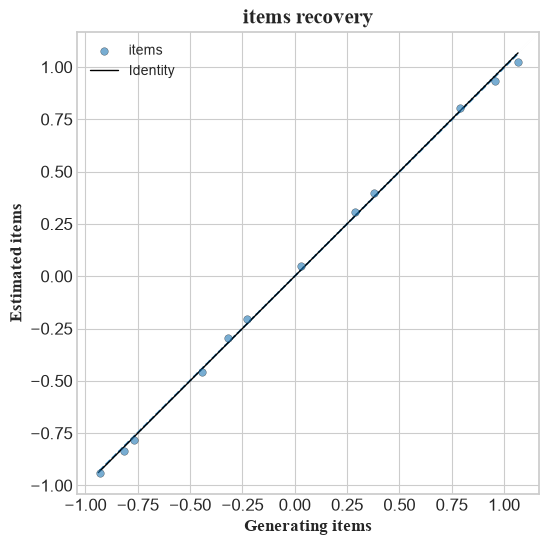

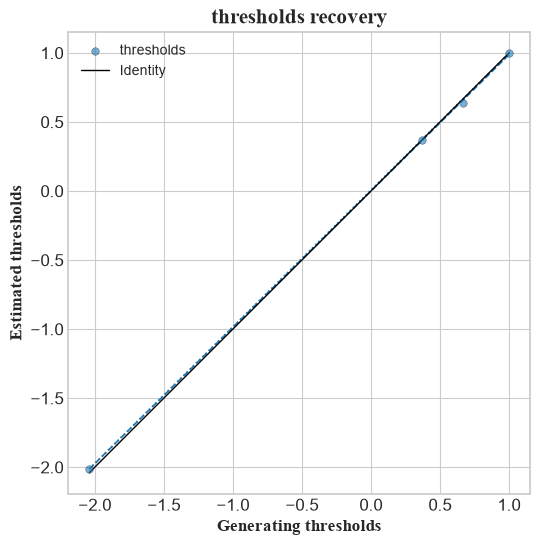

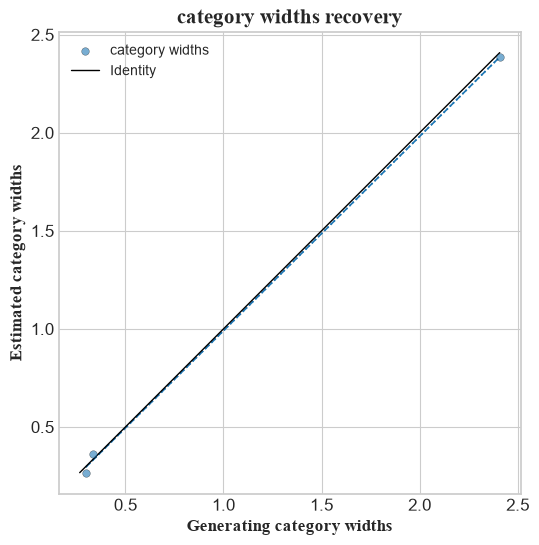

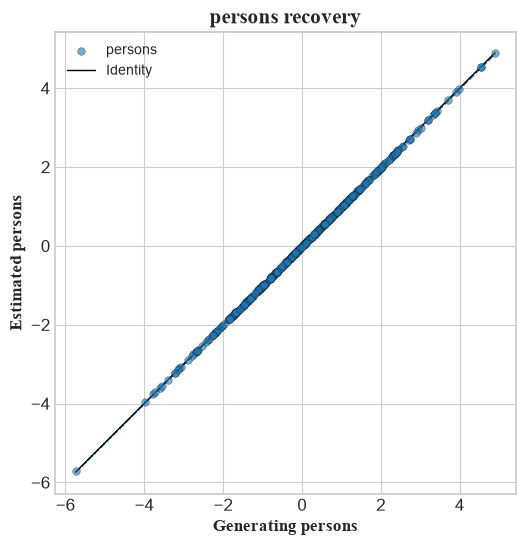

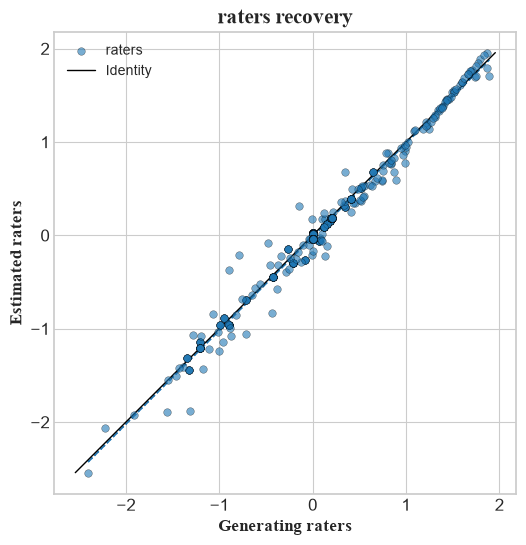

In [30]:
mfrm.recovery_stats(model='mixed')

In [41]:
mfrm.recovery.items.summary

,Overall
RMSE,0.021747
MAE,0.019738
bias,0.0
r,0.999477
r_squared,0.998955
SD_ratio,0.996581
OLS_slope,0.99606
OLS_intercept,0.0
Huber_slope,0.999726
Huber_intercept,0.001541


#### 7. Plots

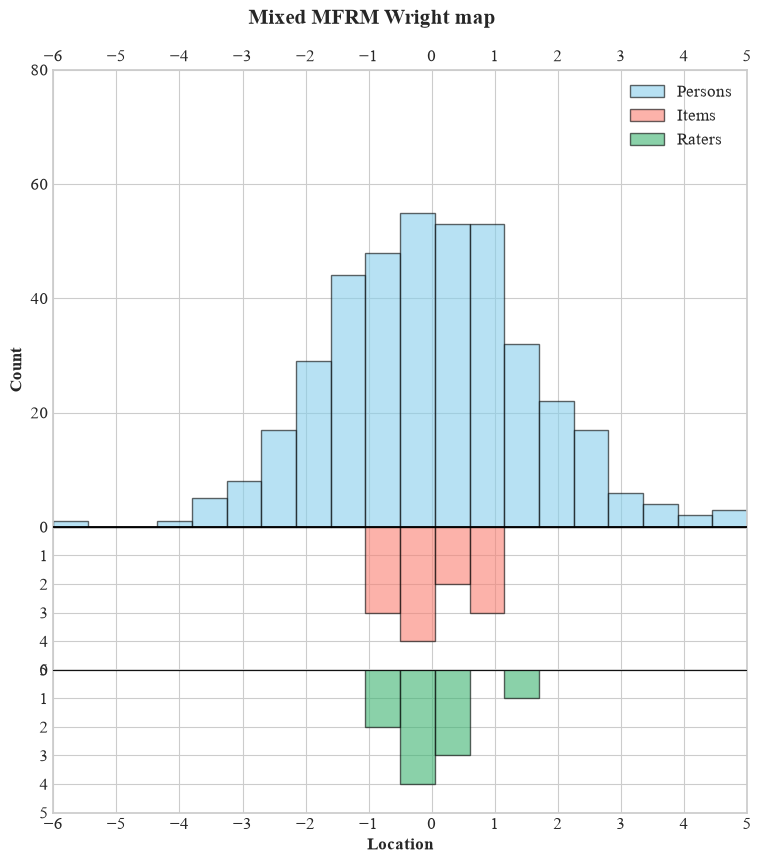

In [32]:
mfrm.wright_map(model='mixed',
                title='Mixed MFRM Wright map',
                filename='my_mfrm_mixed_wright_map')

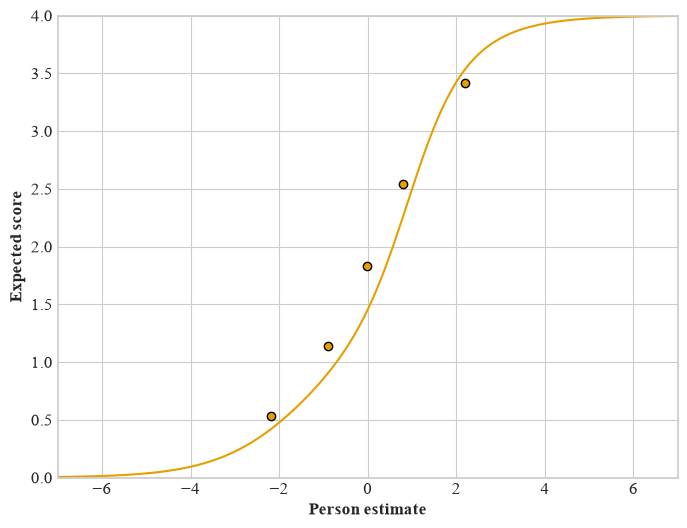

In [33]:
mfrm.icc(model='mixed',
         items='Item_2',
         obs=True,
         xmin=-7,
         xmax=7,
         filename='my_mfrm_mixed_icc')

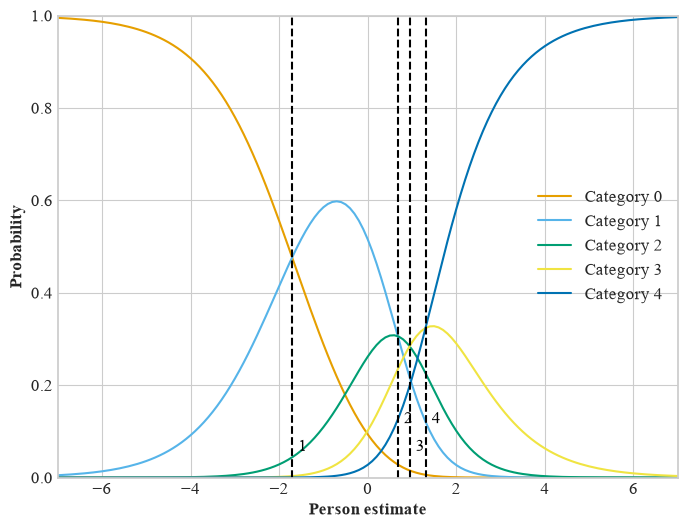

In [34]:
mfrm.crcs(model='mixed',
          item='Item_2',
          thresh_lines=True,
          xmin=-7,
          xmax=7,
          filename='my_mfrm_mixed_crcs')

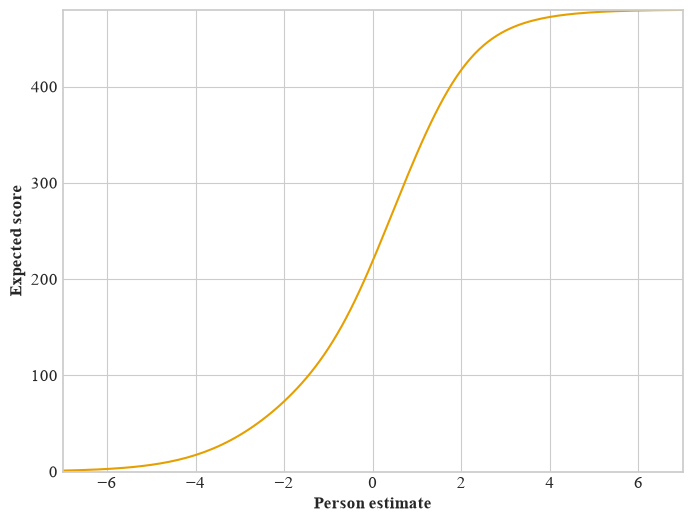

In [35]:
mfrm.tcc(model='mixed',
         xmin=-7,
         xmax=7,
         filename='my_mfrm_mixed_tcc')

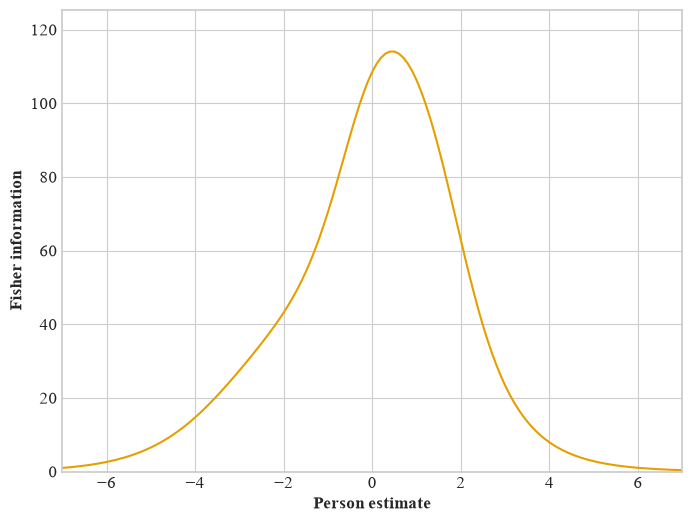

In [36]:
mfrm.test_info(model='mixed',
               xmin=-7,
               xmax=7,
               filename='my_mfrm_mixed_test_info')

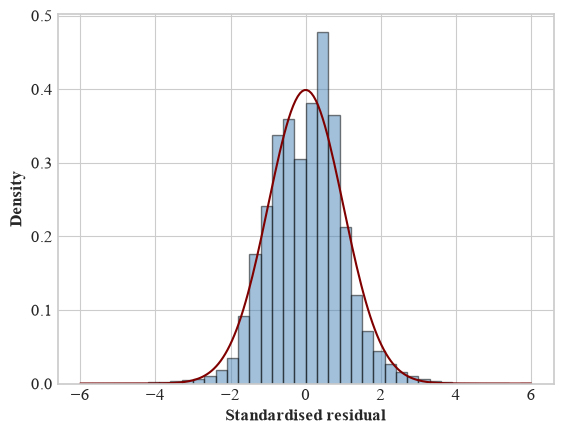

In [37]:
mfrm.std_residuals_plot(model='mixed',
                        bin_width=0.6,
                        normal=True,
                        filename='my_mfrm_mixed_std_residuals_plot')

#### References

Andersen, E. B. (1970). Asymptotic properties of conditional maximum-likelihood estimators. *Journal of the Royal Statistical Society, Series B*, 32(2), 283–301.